<a href="https://colab.research.google.com/github/EnzoSalvini/Calculo_numerico/blob/main/Atividade19_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 k    x^(k)    y^(k)     z^(k) ||x^(k) - x^(k-1)||_inf
 0 0.000000 0.000000  0.000000                       -
 1 0.600000 2.054545 -0.914545                2.054545
 2 0.988364 2.006711 -0.997002                0.388364
 3 1.000071 2.000279 -0.999986                0.011708
 4 1.000025 2.000004 -1.000005                0.000276
 5 1.000001 2.000000 -1.000000                0.000024
 6 1.000000 2.000000 -1.000000                0.000001


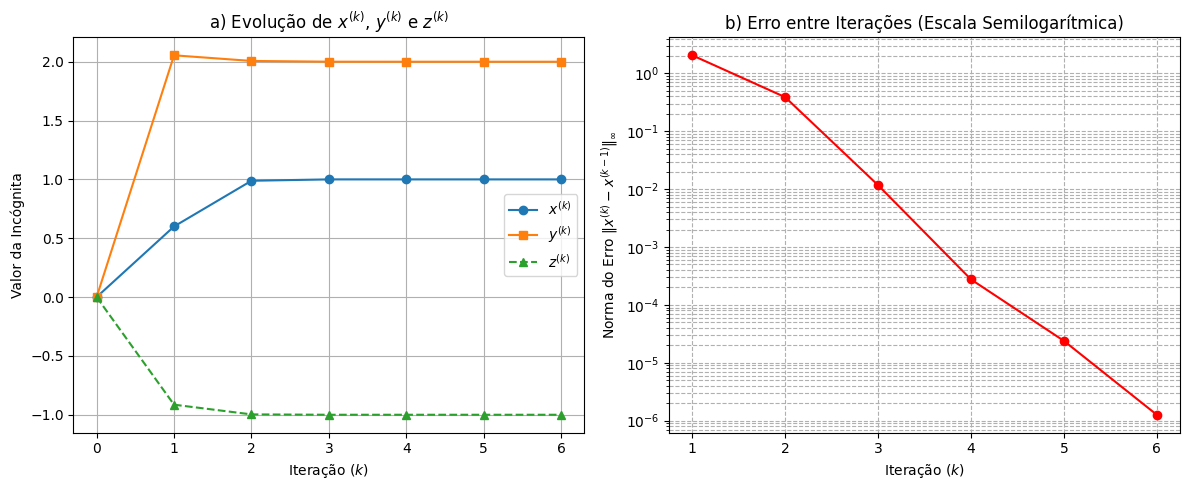

In [ ]:
import numpy as np
import pandas as pd

def gauss_seidel(tol=1e-5, max_iter=100):
    # Condições iniciais
    x = 0.0
    y = 0.0
    z = 0.0

    historico = []

    # Adiciona iteração 0
    historico.append({
        'k': 0,
        'x^(k)': x,
        'y^(k)': y,
        'z^(k)': z,
        '||x^(k) - x^(k-1)||_inf': '-'
    })

    for k in range(1, max_iter + 1):
        x_old, y_old, z_old = x, y, z

        # Fórmulas de atualização
        x = (6.0 + y_old - 2.0 * z_old) / 10.0
        y = (22.0 + x + z_old) / 11.0
        z = (-10.0 - 2.0 * x + y) / 10.0

        # Erro (Norma Infinito)
        erro = max(abs(x - x_old), abs(y - y_old), abs(z - z_old))

        historico.append({
            'k': k,
            'x^(k)': x,
            'y^(k)': y,
            'z^(k)': z,
            '||x^(k) - x^(k-1)||_inf': erro
        })

        if erro < tol:
            break

    return pd.DataFrame(historico)

df_resultados = gauss_seidel()
print(df_resultados.to_string(index=False))

import matplotlib.pyplot as plt

# Extração dos dados do DataFrame
k_vals = df_resultados['k']
x_vals = df_resultados['x^(k)']
y_vals = df_resultados['y^(k)']
z_vals = df_resultados['z^(k)']
erros = df_resultados['||x^(k) - x^(k-1)||_inf'].iloc[1:].astype(float)
k_erros = k_vals[1:]

plt.figure(figsize=(12, 5))

# Gráfico (a): Evolução das Variáveis
plt.subplot(1, 2, 1)
plt.plot(k_vals, x_vals, 'o-', label='$x^{(k)}$')
plt.plot(k_vals, y_vals, 's-', label='$y^{(k)}$')
plt.plot(k_vals, z_vals, '^--', label='$z^{(k)}$')
plt.xlabel('Iteração ($k$)')
plt.ylabel('Valor da Incógnita')
plt.title('a) Evolução de $x^{(k)}$, $y^{(k)}$ e $z^{(k)}$')
plt.grid(True)
plt.legend()

# Gráfico (b): Erro em Escala Logarítmica
plt.subplot(1, 2, 2)
plt.semilogy(k_erros, erros, 'ro-', linewidth=1.5)
plt.xlabel('Iteração ($k$)')
plt.ylabel(r'Norma do Erro $\|x^{(k)} - x^{(k-1)}\|_\infty$')
plt.title('b) Erro entre Iterações (Escala Semilogarítmica)')
plt.grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()